# Overview

This notebook was put together and presented by Beau Leblond, TA for one of Prince's sections of DS6021. I'll be adding some commentary and adaptations along the way.

In this example, we will use the `framingham` dataset to look at missing data and different ways to handle it. The Framingham Heart Study Dataset includes over 4,240 records, 16 columns, and 15 attributes. The goal of the dataset is to predict whether the patient has 10-year risk of future (CHD) coronary heart disease, and we have used it in our notebooks to learn about Logistic Regression. 

For the example in this notebook, we will predict total cholesterol instead of CHD. (e.g. We'll be doing a linear regression instead of a logistic one.)

We will be looking at what happens when data goes missing, how it impacts model predictions, and ways we can do imputation. 

## Get the data

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
# Read in the framingham dataset and explore missing data. 

framingham = pd.read_csv("framingham.csv")
print(framingham.isna().sum())
print("-----------------------")
print(framingham.shape)


male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64
-----------------------
(4240, 16)


## Exploring features of interest

Numeric variables we want to explore: `age`, `cigsPerDay`, `totChol`, `sysBP`, `BMI`

We will use `totChol` as the target variable

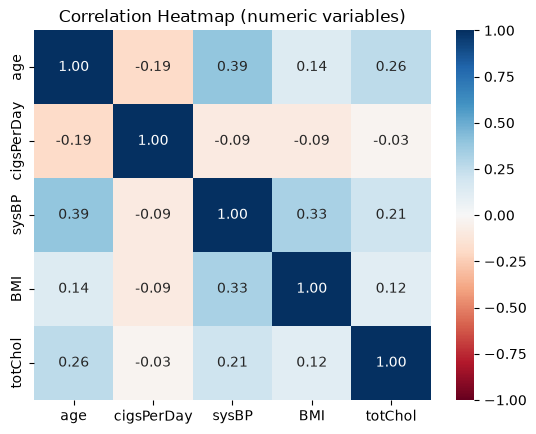

In [3]:
#Let's first look at the correlation across all of these numeric variables
num_cols = ['age', 'cigsPerDay', 'sysBP', 'BMI', 'totChol']
corr = framingham[num_cols].corr()

sns.heatmap(
    corr, annot=True, fmt=".2f",
    cmap="RdBu", vmin=-1, vmax=1
)
plt.title("Correlation Heatmap (numeric variables)")
plt.show()

## Predicting total cholesterol with different amounts of missing data

In [4]:
# Let's predict total cholesterol -- This cell is going to error!

predictors = ['age', 'cigsPerDay', 'sysBP', 'BMI']
framingham_cc = framingham[predictors + ['totChol']]

X = framingham_cc[predictors]
y = framingham_cc['totChol']

model1_sk = LinearRegression().fit(X, y)

print(model1_sk.intercept_)
print(dict(zip(predictors, model1_sk.coef_)))
print(model1_sk.score(X, y))  # R^2

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

## Approach #1: Drop all rows with any missing values from the original dataset

In [5]:
# Sklearn does not automatically handle missing predictors. This is a good thing from a software engineering perspective. 
# You don't want functions to secretly do calculations that your users are not aware of. 
# In order to use sklearn, we either need to drop them or determine an imputation technique


# Let's try a few approaches - first, we will simply drop all of the NA values
predictors = ['age', 'cigsPerDay', 'sysBP', 'BMI']
framingham_cc = framingham[predictors + ['totChol']].dropna()

X = framingham_cc[predictors]
y = framingham_cc['totChol']

model1_sk = LinearRegression().fit(X, y)

print(f"Number of rows: {framingham_cc.shape[0]:,}  |  Columns: {framingham_cc.shape[1]}")
print(f"Intercept: {model1_sk.intercept_:.4f}")
print("Coefficients:")
for name, coef in zip(predictors, model1_sk.coef_):
    print(f"  {name:<12} {coef:>10.4f}")
print(f"R²: {model1_sk.score(X, y):.4f}")

Number of rows: 4,143  |  Columns: 5
Intercept: 134.2330
Coefficients:
  age              1.1522
  cigsPerDay       0.1115
  sysBP            0.2207
  BMI              0.5886
R²: 0.0871


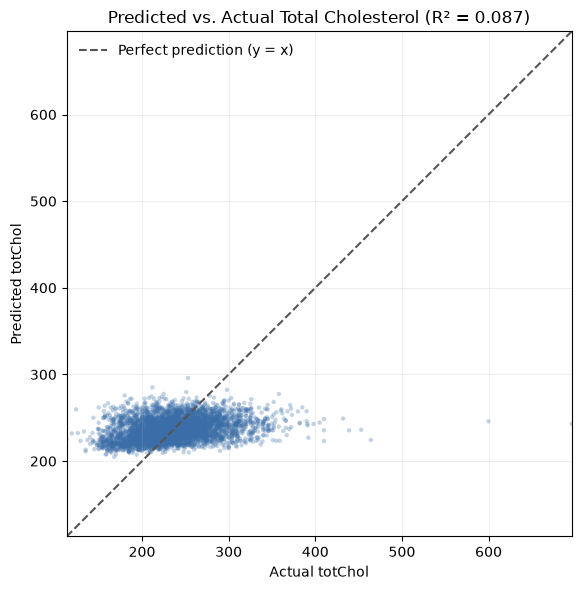

In [6]:
# Let's plot actual vs predicted to explore why our R2 value is so bad. 
y_pred = model1_sk.predict(X)
r2 = model1_sk.score(X, y)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y, y_pred, s=10, alpha=0.3, color="#3b6ea8", edgecolor="none")

# y = x reference line: perfect predictions would fall on it
lims = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
ax.plot(lims, lims, color="#555555", linewidth=1.5, linestyle="--", label="Perfect prediction (y = x)")

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal")
ax.set_xlabel("Actual totChol")
ax.set_ylabel("Predicted totChol")
ax.set_title(f"Predicted vs. Actual Total Cholesterol (R² = {r2:.3f})")
ax.grid(alpha=0.2)
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

## Approach #2: Manually remove 80% of the remaining blood pressure values and see what happens

Note that we will keep Approach #1 (the original dataset with the missing values dropped) as our "base" dataset for the rest of this lab. 

In [7]:
## Randomly delete 80% of blood pressure data

# First we'll make a copy of the original data frame
missing_framingham = framingham.copy()

# In this new data frame, let's randomly delete 80% of the values for sysBP
# We are choosing a random seed so the results are repeatable. 
missing_framingham.loc[missing_framingham.sample(frac=0.8, random_state=567).index, 'sysBP'] = np.nan

Below, we will fit the model again, but this time we will use statsmodels, which handles missing values automatically. 

In [8]:
# First let's fit the models and look at how much data was used in each case. 

model1 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=framingham).fit()
model2 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=missing_framingham).fit()

print(f"Number of observations used in model 1: {model1.nobs}")
print(f"Number of observations used in model 2: {model2.nobs}")


Number of observations used in model 1: 4143.0
Number of observations used in model 2: 829.0


From the output above, we can see that ```smf.ols``` silently dropped the missing data, and model 2 has about 20% of the data of model 1, which aligns with us dropping 80% of the values. 

Now, let's compare the coefficients. Note that model1 should give the same values as our sklearn model for the same number of observations. We will consider Model 1 as our baseline, since we deleted the smallest amount of data, and did not have to impute anything. 

In [9]:
models = {"model1 (framingham)": model1, "model2 (missing_framingham)": model2}

comparison = pd.DataFrame({
    label: pd.concat([m.params, pd.Series({"R²": m.rsquared, "Rows used": m.nobs})])
    for label, m in models.items()
})

formatted = comparison.map("{:.4f}".format)
formatted.loc["Rows used"] = comparison.loc["Rows used"].map("{:,.0f}".format)
formatted

,model1 (framingham),model2 (missing_framingham)
Intercept,134.2330,117.2945
age,1.1522,1.3827
cigsPerDay,0.1115,0.1058
sysBP,0.2207,0.1423
BMI,0.5886,1.1139
R²,0.0871,0.1042
Rows used,"4,143",829


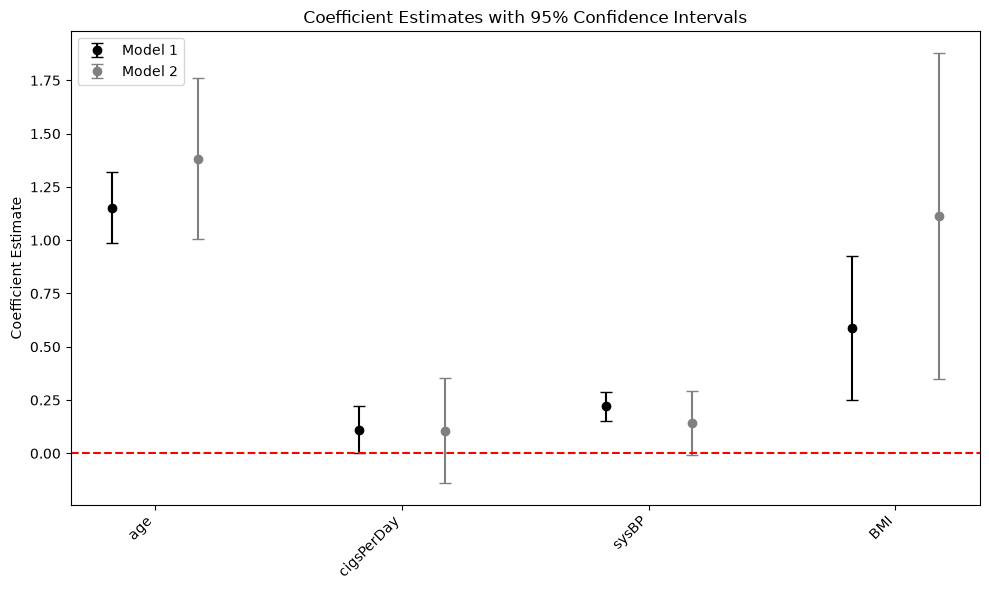

In [10]:
# Now, lets plot the confidence intervals for each of the coefficients.
# We want to look at how they change when we have only a fraction of the data 

def coef_table(model):
    """Coefficients and 95% CIs, without the intercept."""
    table = model.conf_int().drop("Intercept")
    table.columns = ["lower", "upper"]
    table["coef"] = model.params.drop("Intercept")
    return table

models = {"Model 1": (model1, "black"), "Model 2": (model2, "gray")}
tables = {name: coef_table(m) for name, (m, _) in models.items()}
common_vars = tables["Model 1"].index.intersection(tables["Model 2"].index)

x = np.arange(len(common_vars))
width = 0.35  # spacing between bars

plt.figure(figsize=(10, 6))
for offset, (name, (_, color)) in zip([-width/2, width/2], models.items()):
    t = tables[name].loc[common_vars]
    plt.errorbar(
        x + offset, t["coef"],
        yerr=[t["coef"] - t["lower"], t["upper"] - t["coef"]],
        fmt='o', color=color, ecolor=color, capsize=4, label=name
    )

plt.axhline(0, color='red', linestyle='--')
plt.xticks(x, common_vars, rotation=45, ha='right')
plt.ylabel('Coefficient Estimate')
plt.title('Coefficient Estimates with 95% Confidence Intervals')
plt.legend()
plt.tight_layout()
plt.show()

### Questions to consider

What happened when we fit the model again? Why are the confidence intervals different for our parameters?

Is the blood pressure variable now missing completely at random, missing at random, or missing not at random? Why?

## Approach #3: Use mean imputation on the missing data

Now let's take the missing values and impute the mean BP value for each of them. Then, let's refit the model and note the differences in fit and coefficient estimates.

Note: In the cell below are using the mean values from the missing dataset. Why might we be doing this instead of using the mean values from the full dataset? 

In [11]:
# First, make a copy of the missing dataset
mean_framingham  = missing_framingham.copy()

# Calculate the mean sysBP and impute that for the missing values
mean_sysBP = mean_framingham['sysBP'].mean(skipna=True)
mean_framingham['sysBP'] = mean_framingham['sysBP'].fillna(mean_sysBP)

model3 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=mean_framingham).fit()


In [12]:
# Now let's compare results with models 1 and 2 above
models = {"model1 (framingham)": model1, "model2 (missing_framingham)": model2,
          "model3 (mean imputation)": model3}

comparison = pd.DataFrame({
    label: pd.concat([m.params, pd.Series({"R²": m.rsquared, "Rows used": m.nobs})])
    for label, m in models.items()
})

formatted = comparison.map("{:.4f}".format)
formatted.loc["Rows used"] = comparison.loc["Rows used"].map("{:,.0f}".format)
formatted

,model1 (framingham),model2 (missing_framingham),model3 (mean imputation)
Intercept,134.2330,117.2945,125.2827
age,1.1522,1.3827,1.3259
cigsPerDay,0.1115,0.1058,0.1121
sysBP,0.2207,0.1423,0.1685
BMI,0.5886,1.1139,0.8588
R²,0.0871,0.1042,0.0793
Rows used,"4,143",829,"4,143"


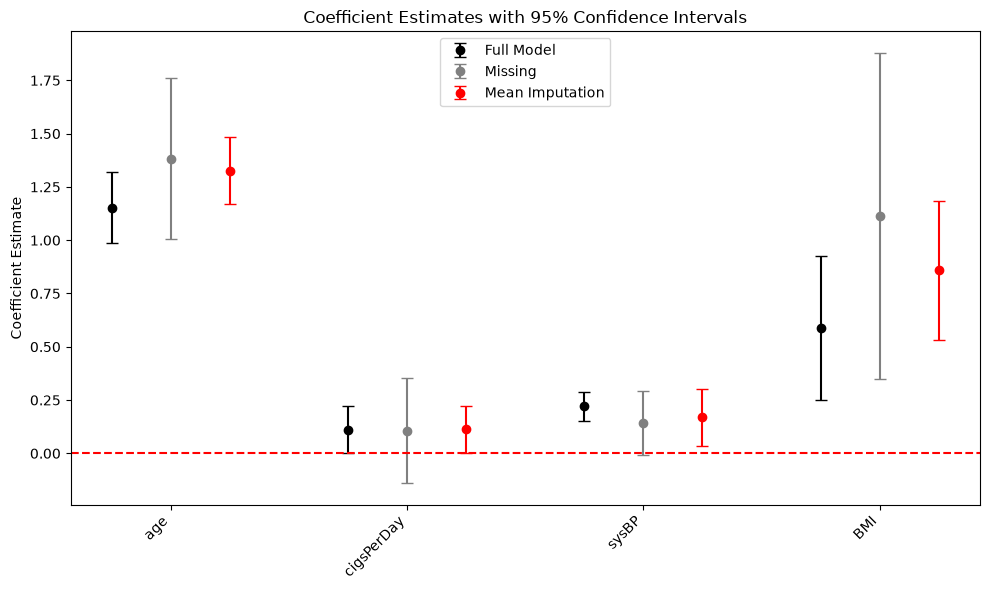

In [13]:
models = {
    "Full Model": (model1, "black"),
    "Missing": (model2, "gray"),
    "Mean Imputation": (model3, "red"),
}
tables = {name: coef_table(m) for name, (m, _) in models.items()}

common_vars = tables["Full Model"].index
for t in tables.values():
    common_vars = common_vars.intersection(t.index)

x = np.arange(len(common_vars))
width = 0.25  # spacing between bars
offsets = (np.arange(len(models)) - (len(models) - 1) / 2) * width  # -width, 0, +width

plt.figure(figsize=(10, 6))
for offset, (name, (_, color)) in zip(offsets, models.items()):
    t = tables[name].loc[common_vars]
    plt.errorbar(
        x + offset, t["coef"],
        yerr=[t["coef"] - t["lower"], t["upper"] - t["coef"]],
        fmt='o', color=color, ecolor=color, capsize=4, label=name
    )

plt.axhline(0, color='red', linestyle='--')
plt.xticks(x, common_vars, rotation=45, ha='right')
plt.ylabel('Coefficient Estimate')
plt.title('Coefficient Estimates with 95% Confidence Intervals')
plt.legend()
plt.tight_layout()
plt.show()

## Approach #4: Impute sysBP using other data in the dataset

Now, instead of using mean imputation, predict sysBP from age, cigsPerDay, and BMI and see how we do. 

In [14]:
# Using the observed data, predict sysBP from age, cigsPerDay, and BMI
observed = missing_framingham[missing_framingham['sysBP'].notna()]
missing = missing_framingham[missing_framingham['sysBP'].isna()]

formula = "sysBP ~ age + cigsPerDay + BMI"
imputer_model = smf.ols(formula, data=observed).fit()

In [15]:
# Now, predict missing values for sysBP using the imputer_model
predicted = imputer_model.predict(missing)

#Add residual noise to preserve variance
residual_std = np.std(imputer_model.resid)
noise_seed = 123
rng = np.random.default_rng(noise_seed)
imputed_values = predicted + rng.normal(0, residual_std, size=len(predicted))

#Fill missing values
missing_framingham.loc[missing.index, 'sysBP'] = imputed_values

In [16]:
# Now let's predict total cholesterol using our predicted values of sysBP
model4 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=missing_framingham).fit()

# Compare with the other models
models = {"model1 (framingham)": model1, "model2 (missing_framingham)": model2,
          "model3 (mean imputation)": model3, "model4 (regression imputation)": model4}

comparison = pd.DataFrame({
    label: pd.concat([m.params, pd.Series({"R²": m.rsquared, "Rows used": m.nobs})])
    for label, m in models.items()
})

formatted = comparison.map("{:.4f}".format)
formatted.loc["Rows used"] = comparison.loc["Rows used"].map("{:,.0f}".format)
formatted


,model1 (framingham),model2 (missing_framingham),model3 (mean imputation),model4 (regression imputation)
Intercept,134.2330,117.2945,125.2827,144.1388
age,1.1522,1.3827,1.3259,1.3396
cigsPerDay,0.1115,0.1058,0.1121,0.1136
sysBP,0.2207,0.1423,0.1685,0.0157
BMI,0.5886,1.1139,0.8588,0.8940
R²,0.0871,0.1042,0.0793,0.0780
Rows used,"4,143",829,"4,143","4,143"


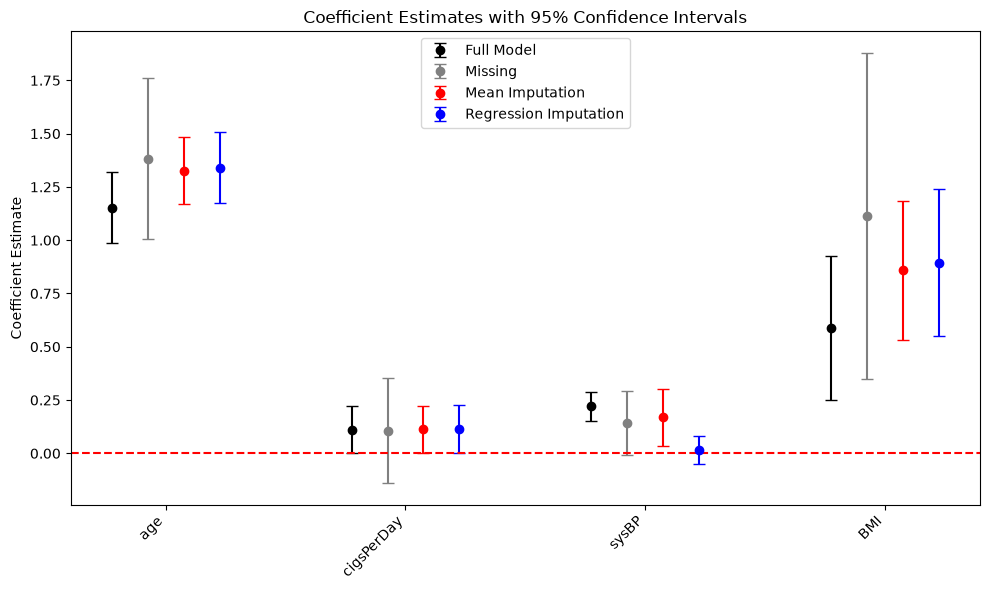

In [17]:
models = {
    "Full Model": (model1, "black"),
    "Missing": (model2, "gray"),
    "Mean Imputation": (model3, "red"),
    "Regression Imputation": (model4, "blue")
}
tables = {name: coef_table(m) for name, (m, _) in models.items()}

common_vars = tables["Full Model"].index
for t in tables.values():
    common_vars = common_vars.intersection(t.index)

x = np.arange(len(common_vars))
width = 0.6/len(models)  # spacing between bars
offsets = (np.arange(len(models)) - (len(models) - 1) / 2) * width  # -width, 0, +width

plt.figure(figsize=(10, 6))
for offset, (name, (_, color)) in zip(offsets, models.items()):
    t = tables[name].loc[common_vars]
    plt.errorbar(
        x + offset, t["coef"],
        yerr=[t["coef"] - t["lower"], t["upper"] - t["coef"]],
        fmt='o', color=color, ecolor=color, capsize=4, label=name
    )

plt.axhline(0, color='red', linestyle='--')
plt.xticks(x, common_vars, rotation=45, ha='right')
plt.ylabel('Coefficient Estimate')
plt.title('Coefficient Estimates with 95% Confidence Intervals')
plt.legend()
plt.tight_layout()
plt.show()